## ZOMATO ANALYSIS PROJECT

### STEP 1 - IMPORTING LIBRARIES

In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### STEP 2 - IMPORTING DATASET

In [3]:
data_set = pd.read_csv("Zomato data .csv")

### STEP 3 - EXPLORING DATASET

In [4]:
data_set.head()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


In [5]:
data_set.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   name                         148 non-null    object
 1   online_order                 148 non-null    object
 2   book_table                   148 non-null    object
 3   rate                         148 non-null    object
 4   votes                        148 non-null    int64 
 5   approx_cost(for two people)  148 non-null    int64 
 6   listed_in(type)              148 non-null    object
dtypes: int64(2), object(5)
memory usage: 8.2+ KB


In [6]:
data_set.isnull().sum()

name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
approx_cost(for two people)    0
listed_in(type)                0
dtype: int64

### STEP 4 - CHANGING DATA TYPE OF RATE COLUMN

In [7]:
def handle_rate(value):
    value = str(value).split('/')
    value = value[0]
    return float(value)

data_set['rate'] = data_set['rate'].apply(handle_rate)
# apply() = runs a function (here handle_rate) for each value in a column
data_set.head()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


### STEP 5 - ANALYZING DATASET TO ANSWER SOME QNS

#### QN 1 : What type of restaurant do the majority of customers order from ?

Text(0, 0.5, 'Count Of Customers')

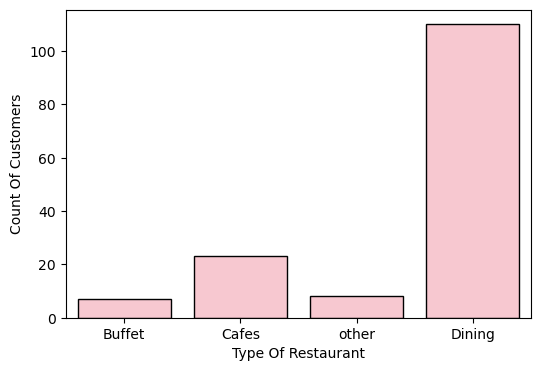

In [8]:
plt.figure(figsize = (6,4))
sns.countplot(x = data_set['listed_in(type)'] ,color ='pink', edgecolor = 'black')
# count plot = counts how many time each category appears. 
# used when comparing multiple groups

plt.xlabel("Type Of Restaurant")
plt.ylabel("Count Of Customers")

CONCLUSION 1 : Dining type of restaurants own the majority of customers

#### QN 2 : How many votes has each type of restaurants recieved from customers ?

Text(0, 0.5, 'Votes')

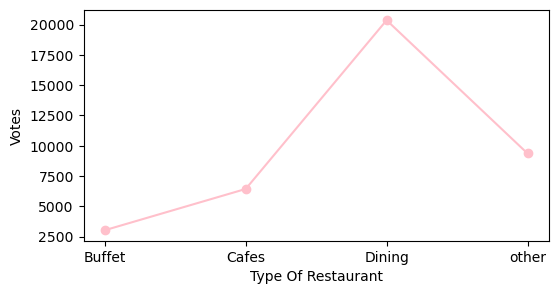

In [9]:
grouped_data = data_set.groupby('listed_in(type)')['votes'].sum()
result = pd.DataFrame({'votes':grouped_data})

plt.figure(figsize = (6,3))
plt.plot(result, color = 'pink', marker= 'o')
# line chart = connects values across categories with a line
# great for comparing total

plt.xlabel("Type Of Restaurant")
plt.ylabel("Votes")

CONCLUSION 2 : Dining type of restaurants own the majority of customer votes ( around 20K )

#### QN 3 : What are the ratings that the majority of restaurants have recieved ? 

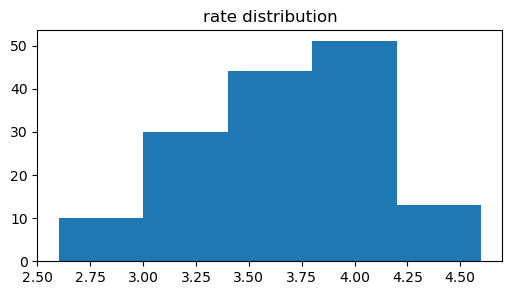

In [24]:
plt.figure(figsize = (6,3))
plt.hist(data_set['rate'], bins=5)
# histogram = shows how a numerical column is distributed by grouping values into bins
plt.title('rate distribution')
plt.show()

#### QN 4 : Zomato has observed that most couples order most of their food online. What is their average spending on each order.

<Axes: xlabel='approx_cost(for two people)', ylabel='count'>

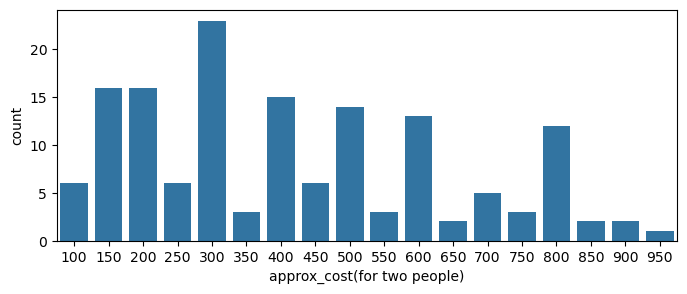

In [23]:
plt.figure(figsize = (8,3))
couple_avg = data_set['approx_cost(for two people)']
sns.countplot(x = couple_avg)

#### QN 5 : Which mode has recieved maximum ratings ?

<Axes: xlabel='online_order', ylabel='rate'>

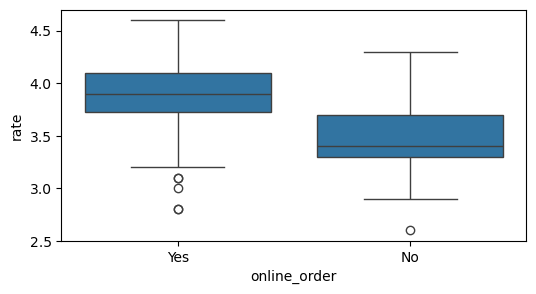

In [20]:
plt.figure(figsize = (6,3))
sns.boxplot(x = 'online_order' , y ='rate' , data = data_set)
# box plot = shows meadian , spread (iqr) and outliners

#### QN 6 : Which type of restaurant recieved more offline orders ? Answer so that zomato can provide customers with some good offers.

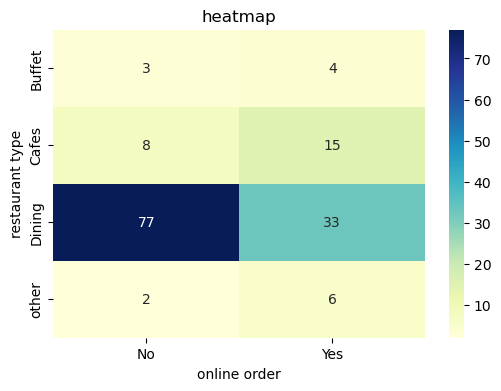

In [26]:
plt.figure(figsize = (6,4))
pivot_t = data_set.pivot_table(index='listed_in(type)' , columns='online_order' , aggfunc='size',fill_value=0)
sns.heatmap(pivot_t , annot= True, cmap="YlGnBu", fmt='d')
# heat map = colour coded grid built from pivot table
plt.title("heatmap")
plt.xlabel("online order")
plt.ylabel("restaurant type")
plt.show()